In [30]:
import re
import string
from tqdm import tqdm
import numpy as np
import pickle
import random
import scipy.sparse as sparse
from scipy.sparse.linalg import svds
import seaborn as sns
import matplotlib.pyplot as plt


#@title Utility Functions

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def save_models(word_freqs, Vsvd, Vw2v, 
    word2index = None, index2word = None, losses_w2v = None):

    '''
    Save all the appropriate data. We are expecting the variables
    shown below.
    '''
    data = {
        'word_freqs': word_freqs,
        'Vsvd': Vsvd,
        'Vw2v': Vw2v,
        'word2index': word2index,
        'index2word': index2word,
        'losses_w2v': losses_w2v,
    }

    with open('assignment5.pkl', 'wb') as f:
        pickle.dump(data, f)

#@title Print Top K Word Vectors from Vectors Matrix
def print_topk(word, V, word2index, index2word, k=10):
  '''
  Args:
    - word: a string, e.g., "neural" to look up
    - V: a matrix of vectors, size num_words x embedding_size
    - word2index: dictionary of {word: index}
    - index2word: dictionary of {index: word}
    - k: number of words to print
  '''
  print("Top ", k, " words closest to ", word, ":")

  # Normalize the vectors
  V_normalized = V / np.linalg.norm(V, axis=1, keepdims=True)

  correlations = V_normalized[word2index[word]] @ V_normalized.T
  topk_indices = np.argsort(correlations)[-k:][::-1]
  for index in topk_indices:
    print(index2word[index], correlations[index])


In [32]:

#@title Question 1

def process_data(filename, min_cnt, max_cnt, min_words = 5, min_letters = 3):
    '''
    Preprocesses and builds the distribution of words in sorted order
    (from maximum occurrence to minimum occurrence) after reading the
    file. Preprocessing will include filtering out:
    * words that have non-letters in them,
    * words that are too short (under minletters)

    Arguments:
        - filename: name of file
        - min_cnt: min occurrence of words to include
        - max_cnt: max occurrence of words to include
        - min_words: minimum number of words in a title after word filtering
        - min_letters: min length of words to include (3)

    Returns:
        - word_freqs: A sorted (max to min) list of tuples of form -

            [(word1, count1), (wordN, countN), ... (wordN, countN)]

        - dataset: A list of strings with OOV words removed -

            ["this is title 1", "this is title 2", ...]
    '''
    #<YOUR-CODE-HERE
    tokenized_titles = []
    # Read the file, Clean and tokenize titles
    with open(filename, "r", encoding="utf-8") as f:
        for title in f:
            words = title.lower().split()
            
            # Remove punctuation at the beginning and end
            words = [word.strip(string.punctuation) for word in words]
            
            # Keep only alphabetic words with enough letters
            words = [
                word for word in words
                if word.isalpha() and len(word) >= min_letters
            ]

            tokenized_titles.append(words)

    # Count word frequencies
    word_counts = {}

    for words in tokenized_titles:
        for word in words:
            word_counts[word] = word_counts.get(word, 0) + 1

    word_freqs = []
    # Filter words by frequency
    for word, cnt in word_counts.items():
        if cnt <= max_cnt and cnt >= min_cnt:
            word_freqs.append((word, cnt))

    # Sort by frequency (descending)
    word_freqs.sort(key=lambda x: x[1], reverse=True)

    # Create vocabulary
    vocabulary = set(word for word, count in word_freqs)

    # Remove OOV words and short titles
    dataset = []

    for words in tokenized_titles:
        filtered_words = [
            word for word in words if word in vocabulary
        ]

        if len(filtered_words) >= min_words:
            dataset.append(" ".join(filtered_words))

    return word_freqs, dataset


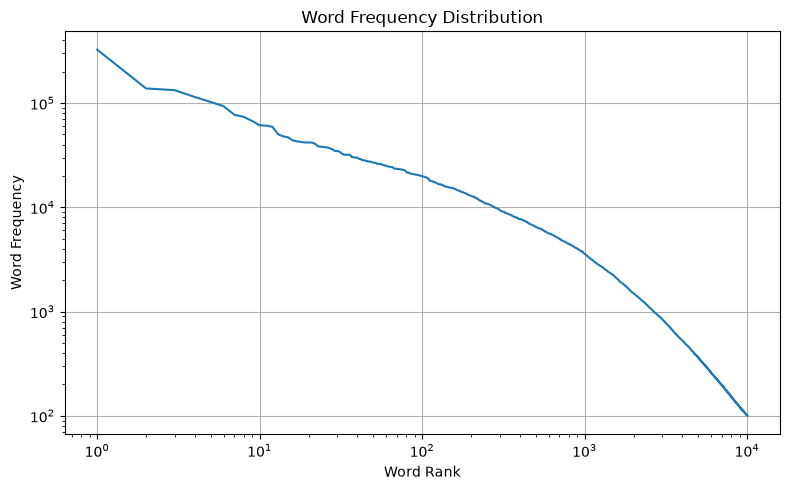

In [33]:

import matplotlib.pyplot as plt
from assignment5 import process_data

# Load word frequencies using Q1
word_freqs, dataset = process_data(
    "arxiv_titles.txt",
    100,
    1e10,
    min_words=5,
    min_letters=4
)

# Extract word frequencies
frequencies = [count for word, count in word_freqs]
ranks = range(1, len(frequencies) + 1)

# Plot word frequency distribution
plt.figure(figsize=(8, 5))
plt.plot(ranks, frequencies)

plt.xlabel("Word Rank")
plt.ylabel("Word Frequency")
plt.title("Word Frequency Distribution")
plt.xscale("log")
plt.yscale("log")
plt.grid(True)

# Save figure
plt.tight_layout()
plt.savefig("q1_word_frequency.png", dpi=300)
plt.show()


In [12]:

def process_data_test():

  data_test = [
      "A Case for Neural Networks Models: Deeper is Better",
      "Large Language models: Transformers require Data",
      "A United Framework of large language models",
      "A Survey of Neural Translation Models for Large Language Models"
  ]

  with open("test.txt", 'w') as f:
    for title in data_test:
      f.write(title + '\n')

  word_freqs, filtered_dataset = process_data(
      "test.txt", 2, 100, min_words=4, min_letters=4)

  # Expected data after filtering should have the properties that:
  #   - Words appear at least twice, (i.e., models, large, language, neural)
  #   - There are at least four words in the title
  #   - Each word is at least four letters long
  expected_word_freqs = [
      ('models', 5), ('large', 3), ('language', 3), ('neural', 2)
  ]

  expected_filtered_dataset = ['neural models large language models']

  assert word_freqs == expected_word_freqs, "Your word frequencies are incorrect. " \
    "Expected:\n" + str(expected_word_freqs) + "\nReceived:\n" + str(word_freqs)
  assert filtered_dataset == expected_filtered_dataset, "Your filtered dataset is incorrect. " \
    "Expected:\n" + str(expected_filtered_dataset) + "\nReceived:\n" + str(filtered_dataset)

  print("\nprocess_data: \033[1;32mtests OK.\033[0m")

process_data_test()


process_data: tests OK.


In [21]:
#@title Question 2.1

def create_adjacency(dataset, word2index, win = 10):
    '''
    Builds an adjacency matrix based on word co-occurrence within a window.

    Args:
        - dataset: List of processed titles
        - word2index: Dictionary mapping word to index
        - win: The window size for co-occurrence.

    Returns:
        - adjacency_matrix: A NumPy array representing the adjacency matrix.
    '''
    #<YOUR-CODE-HERE>
    # Create an empty adjacency matrix
    vocab_size = len(word2index)
    adjacency_matrix = np.zeros((vocab_size, vocab_size), dtype=np.int32)

    # Go through each title
    for title in dataset:
        words = title.split() # [large,language,models,transformers,require,data]

        # Go through each word
        for i in range(len(words)): # [large

            # Check words within the window # [language,models,transformers,require,data]
            for j in range(i + 1, min(i + win // 2 + 1, len(words))):

                # Get word indices
                idx_i = word2index[words[i]] # idx_large
                idx_j = word2index[words[j]] # idx_language

                # Update co-occurrence counts
                if idx_i != idx_j:
                    adjacency_matrix[idx_i][idx_j] += 1
                    adjacency_matrix[idx_j][idx_i] += 1

    return adjacency_matrix

In [22]:
def create_adjacency_test():

  # Test file
  data_test = [
      "A Case for Neural Networks Models: Deeper is Better",
      "Large Language models: Transformers require Data",
      "A United Framework of Language Models"
  ]
  with open("test.txt", 'w') as f:
    for title in data_test:
      f.write(title + '\n')

  # Obtain word frequencies and dataset
  word_freqs, filtered_dataset = process_data(
      "test.txt", 1, 100, min_words=3, min_letters=3)

  # Create word2index to use in calculating adjacency matrix
  word2index = {word[0]: i for i, word in enumerate(word_freqs)}

  # Run your code
  adjacency_matrix = create_adjacency(filtered_dataset, word2index, win=5)

  # Since we have the option to have counts or boolean, just check boolean
  adjacency_matrix = np.array((adjacency_matrix > 0).astype(int))

  # Expected adjacency matrix
  adjacency_matrix_expected = np.array([
    [ 0,1,0,0,1,1,1,1,1,1,1,0,0,1 ],
    [ 1,0,0,0,0,0,0,0,1,1,0,0,1,1 ],
    [ 0,0,0,1,1,0,0,0,0,0,0,0,0,0 ],
    [ 0,0,1,0,1,1,0,0,0,0,0,0,0,0 ],
    [ 1,0,1,1,0,1,0,0,0,0,0,0,0,0 ],
    [ 1,0,0,1,1,0,1,0,0,0,0,0,0,0 ],
    [ 1,0,0,0,0,1,0,1,0,0,0,0,0,0 ],
    [ 1,0,0,0,0,0,1,0,0,0,0,0,0,0 ],
    [ 1,1,0,0,0,0,0,0,0,0,0,0,0,0 ],
    [ 1,1,0,0,0,0,0,0,0,0,1,1,0,0 ],
    [ 1,0,0,0,0,0,0,0,0,1,0,1,0,0 ],
    [ 0,0,0,0,0,0,0,0,0,1,1,0,0,0 ],
    [ 0,1,0,0,0,0,0,0,0,0,0,0,0,1 ],
    [ 1,1,0,0,0,0,0,0,0,0,0,0,1,0 ]])

  # There should be no difference
  difference = sum(sum( abs(adjacency_matrix - adjacency_matrix_expected)))
  assert difference == 0, "Your adjacency matrix is incorrect. \nExpected:\n" + \
    str(adjacency_matrix_expected) + "\nReceived:\n" + str(adjacency_matrix) + \
    "\n\nDifference:" + str(difference)

  # Tests OK
  print("create_adjacency: \033[1;32mtests OK.\033[0m")

create_adjacency_test()

create_adjacency: tests OK.


In [28]:
#@title Question 2.2

import pandas as pd

def train_svd(adjacency_matrix, min_sv_index = 3, max_sv_index = 103):
    """
    Creates an embedding space using SVD on the adjacency matrix. The two parameters
    min_sv_index and max_sv_index provide the embedding size, where

        embedding_size = max_sv_index - min_sv_index.

    So, if s is a vector of all the singular values sorted from largest to smallest,
    then the embedding matrix will use the vectors corresponding to

        singular_values = s[min_sv_index:max_sv_index]

    Args:
        - adjacency_matrix: The adjacency matrix.
        - min_sv_index: The index of the largest？ singular value to use.
        - max_sv_index: The index of the largest singular value to use

    Returns:
        - A NumPy array representing the embedding space (num_words x embedding_dim)
    """
    #<YOUR-CODE-HERE>
    # Perform SVD
    U, S, Vt = np.linalg.svd(adjacency_matrix)

    # Select singular vectors
    U_fast = U[:, min_sv_index - 1:max_sv_index]

    return U_fast
    

In [34]:
def train_svd_test():

  vocabulary = ['models', 'language', 'case', 'for', 'neural', 'networks',
                'deeper', 'better', 'large', 'transformers', 'require', 'data',
                'united', 'framework']

  adjacency_matrix = np.array([
    [ 0,1,0,0,1,1,1,1,1,1,1,0,0,1 ],
    [ 1,0,0,0,0,0,0,0,1,1,0,0,1,1 ],
    [ 0,0,0,1,1,0,0,0,0,0,0,0,0,0 ],
    [ 0,0,1,0,1,1,0,0,0,0,0,0,0,0 ],
    [ 1,0,1,1,0,1,0,0,0,0,0,0,0,0 ],
    [ 1,0,0,1,1,0,1,0,0,0,0,0,0,0 ],
    [ 1,0,0,0,0,1,0,1,0,0,0,0,0,0 ],
    [ 1,0,0,0,0,0,1,0,0,0,0,0,0,0 ],
    [ 1,1,0,0,0,0,0,0,0,0,0,0,0,0 ],
    [ 1,1,0,0,0,0,0,0,0,0,1,1,0,0 ],
    [ 1,0,0,0,0,0,0,0,0,1,0,1,0,0 ],
    [ 0,0,0,0,0,0,0,0,0,1,1,0,0,0 ],
    [ 0,1,0,0,0,0,0,0,0,0,0,0,0,1 ],
    [ 1,1,0,0,0,0,0,0,0,0,0,0,1,0 ]]).astype(np.float32)

  # Run your code
  U_fast = train_svd(adjacency_matrix, min_sv_index = 1, max_sv_index=8)

  word_vectors = dict()
  for i, word in enumerate(vocabulary):
    word_vectors[word] = U_fast[i]
  
  # Check the sizes of the matrices
  assert adjacency_matrix.shape == (14, 14)
  assert U_fast.shape == (14, 8)

  print("train_svd: \033[1;32mtests OK.\033[0m")

train_svd_test()

train_svd: tests OK.


In [35]:

import pickle
import numpy as np

# Load saved model
with open("assignment5.pkl", "rb") as f:
    data = pickle.load(f)

word_freqs = data["word_freqs"]
Vsvd = data["Vsvd"]

# Create word mappings
vocabulary = [word for word, count in word_freqs]
word2index = {word: i for i, word in enumerate(vocabulary)}
index2word = {i: word for i, word in enumerate(vocabulary)}

# Normalize word vectors
norms = np.linalg.norm(Vsvd, axis=1, keepdims=True)
V_normalized = Vsvd / np.maximum(norms, 1e-12)

# Find the 10 nearest neighbors
words_to_test = ["neural", "machine", "dark", "string", "black"]

for word in words_to_test:
    if word not in word2index:
        print(f"\n{word} is not in the vocabulary.")
        continue

    word_idx = word2index[word]

    similarities = V_normalized @ V_normalized[word_idx]

    # Exclude the query word itself
    similarities[word_idx] = -np.inf

    top_indices = np.argsort(similarities)[-10:][::-1]

    print(f"\nTop 10 nearest neighbors for '{word}' (SVD):")
    for i, idx in enumerate(top_indices, 1):
        print(f"{i}. {index2word[idx]}: {similarities[idx]:.4f}")



Top 10 nearest neighbors for 'neural' (SVD):
1. residual: 0.5302
2. siamese: 0.4974
3. capsule: 0.4816
4. relu: 0.4532
5. neurons: 0.4479
6. regulatory: 0.4384
7. multiplex: 0.4106
8. inception: 0.4075
9. rewiring: 0.3984
10. neuronal: 0.3927

Top 10 nearest neighbors for 'machine' (SVD):
1. multitask: 0.8811
2. dictionary: 0.8804
3. federated: 0.8536
4. reinforcement: 0.8233
5. curriculum: 0.8207
6. contrastive: 0.8106
7. continual: 0.7965
8. imitation: 0.7741
9. lifelong: 0.7122
10. transductive: 0.7033

Top 10 nearest neighbors for 'dark' (SVD):
1. condensed: 0.6857
2. subhalos: 0.5531
3. baryonic: 0.5526
4. haloes: 0.5506
5. warm: 0.5449
6. annihilations: 0.5323
7. dense: 0.5077
8. halos: 0.5059
9. annihilation: 0.4926
10. neutralino: 0.4871

Top 10 nearest neighbors for 'string' (SVD):
1. superstring: 0.9438
2. abjm: 0.8711
3. perturbation: 0.8632
4. iwasawa: 0.8422
5. yang: 0.8311
6. eliashberg: 0.8215
7. effective: 0.8158
8. practice: 0.8157
9. mills: 0.8104
10. mind: 0.7905

T

In [ ]:
#@title Question 3.1

def sample_w2v(data, word2index, neg_samples=5, win=10, sampling_distro=None):
    '''
    Randomly samples a title and a window within that title, returning
    one-hot and multi-hot vectors.

    Args:
        - data: A list of preprocessed titles.
        - word2index: A dictionary of words and their indices
        - neg_samples: Number of negative samples
        - win: The size of the context window.
        - sampling_distro: Sampling distribution of the words, likely Zipfian

    Returns:
        - wi: target vector index
        - wo: context vector index
        - Wn: negative vectors index
    '''
    #<YOUR-CODE-HERE>
    # Randomly select a title
    title = random.choice(data)
    words = title.split()

    # Randomly select a target word
    i = random.randrange(len(words))
    wi = word2index[words[i]]

    # Find context positions
    half_win = win // 2

    left = max(0, i - half_win)
    right = min(len(words), i + half_win + 1)

    context_positions = [
        j for j in range(left, right)
        if j != i
    ]

    # Randomly select a positive context word
    j = random.choice(context_positions)
    wo = word2index[words[j]]

    # Sample negative words
    vocab_size = len(word2index)

    Wn = np.random.choice(
        vocab_size,
        size=neg_samples,
        replace=True,
        p=sampling_distro
    )

    return wi, wo, Wn


Number of iterations: 1000000


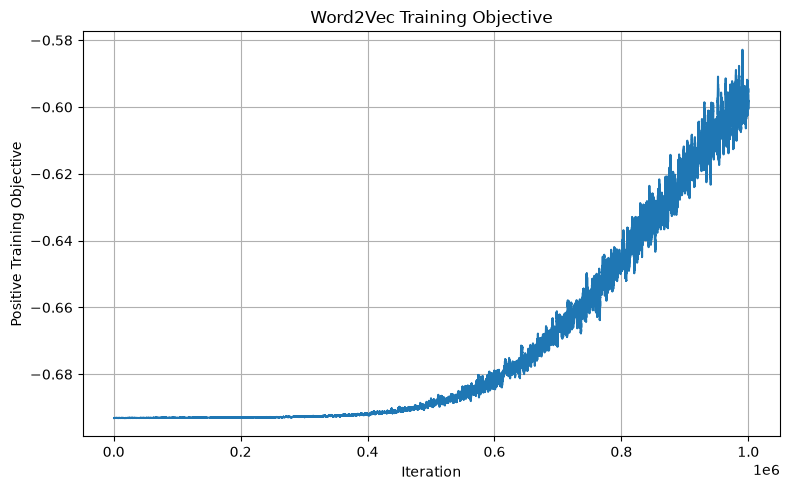

In [37]:

import numpy as np
import matplotlib.pyplot as plt

# Load training objective
losses = np.load("q3_w2v_objective.npy")

print("Number of iterations:", len(losses))

# Smooth the curve
window = 1000
smoothed = np.convolve(
    losses,
    np.ones(window) / window,
    mode="valid"
)

iterations = np.arange(window, len(losses) + 1)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(iterations, smoothed)

plt.xlabel("Iteration")
plt.ylabel("Positive Training Objective")
plt.title("Word2Vec Training Objective")
plt.grid(True)
plt.tight_layout()

# Save figure
plt.savefig("q3_w2v_training.png", dpi=300)
plt.show()


Number of iterations: 1000000


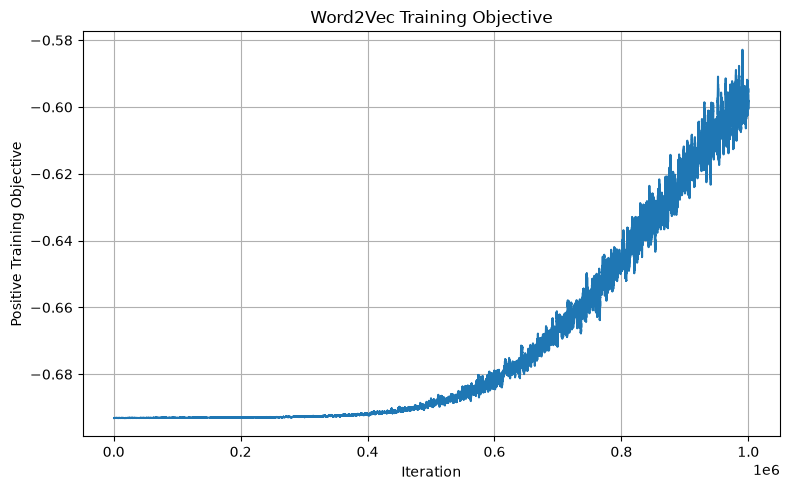

In [38]:

import numpy as np
import matplotlib.pyplot as plt

# Load training objective
losses = np.load("q3_w2v_objective.npy")

print("Number of iterations:", len(losses))

# Smooth the curve
window = 1000
smoothed = np.convolve(
    losses,
    np.ones(window) / window,
    mode="valid"
)

iterations = np.arange(window, len(losses) + 1)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(iterations, smoothed)

plt.xlabel("Iteration")
plt.ylabel("Positive Training Objective")
plt.title("Word2Vec Training Objective")
plt.grid(True)
plt.tight_layout()

# Save figure
plt.savefig("q3_w2v_training.png", dpi=300)
plt.show()


In [39]:

import pickle
import numpy as np

# Load the trained Word2Vec model
with open("assignment5.pkl", "rb") as f:
    data = pickle.load(f)

word_freqs = data["word_freqs"]

# Word2Vec contains two matrices: Vi and Vo
Vi, Vo = data["Vw2v"]

# Create word mappings
vocabulary = [word for word, count in word_freqs]
word2index = {
    word: i for i, word in enumerate(vocabulary)
}
index2word = {
    i: word for i, word in enumerate(vocabulary)
}

# Normalize Word2Vec input vectors
norms = np.linalg.norm(Vi, axis=1, keepdims=True)
V_normalized = Vi / np.maximum(norms, 1e-12)

# Target words
words_to_test = [
    "neural",
    "machine",
    "dark",
    "string",
    "black"
]

# Find the 10 nearest neighbors
for word in words_to_test:

    if word not in word2index:
        print(f"\n'{word}' is not in the vocabulary.")
        continue

    word_idx = word2index[word]

    # Compute cosine similarities
    similarities = V_normalized @ V_normalized[word_idx]

    # Exclude the target word itself
    similarities[word_idx] = -np.inf

    # Get top 10 neighbors
    top_indices = np.argsort(similarities)[-10:][::-1]

    print(f"\nTop 10 nearest neighbors for '{word}' (Word2Vec):")

    for rank, idx in enumerate(top_indices, start=1):
        neighbor = index2word[idx]
        score = similarities[idx]

        print(f"{rank}. {neighbor}: {score:.4f}")



Top 10 nearest neighbors for 'neural' (Word2Vec):
1. graph: 0.9791
2. classification: 0.9752
3. learning: 0.9738
4. using: 0.9737
5. detection: 0.9732
6. based: 0.9723
7. adversarial: 0.9719
8. generative: 0.9716
9. image: 0.9709
10. convolutional: 0.9701

Top 10 nearest neighbors for 'machine' (Word2Vec):
1. deep: 0.9927
2. reinforcement: 0.9890
3. representation: 0.9835
4. federated: 0.9803
5. active: 0.9712
6. based: 0.9711
7. using: 0.9698
8. algorithms: 0.9687
9. transfer: 0.9684
10. approach: 0.9683

Top 10 nearest neighbors for 'dark' (Word2Vec):
1. mass: 0.9373
2. energy: 0.9372
3. nuclear: 0.9353
4. search: 0.9335
5. high: 0.9330
6. constraints: 0.9313
7. gravitational: 0.9308
8. production: 0.9306
9. quark: 0.9279
10. light: 0.9273

Top 10 nearest neighbors for 'string' (Word2Vec):
1. local: 0.9674
2. model: 0.9666
3. theory: 0.9665
4. system: 0.9662
5. effective: 0.9661
6. field: 0.9659
7. properties: 0.9658
8. systems: 0.9656
9. nonlinear: 0.9653
10. dynamics: 0.9653

Top 